# Phase 4 — Practical implications (supporting analysis)

This notebook runs [`phase4_analysis.py`](phase4_analysis.py), which **reads** Phase 2/3 data and outputs and
writes only to `outputs/tables/phase4/` and `outputs/figures/phase4/`. No model is trained or tuned.
The written answers are in [`RESULTS.md`](RESULTS.md) and the one-page utility summary in
[`Recommendation.md`](../Recommendation.md) (repository root).

> **Assumption — study window:** weekdays 16:00–18:59 **UK local clock time** (Europe/London), chosen for this
> study. It is a common evening-peak window, not a universal or official UK peak definition.

> **Assumption — households:** Houses 2, 7, 8, 9 and 15 with Phase 3's usability masks. House 5 stays excluded
> (probable washer-dryer).

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

here = Path.cwd()
sys.path.insert(0, str(here if (here / "phase4_analysis.py").exists() else here / "phase4"))
import phase4_analysis as a

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
res = a.run_all(verbose=False)

## 1 · The study window is defined on the local clock (daylight saving handled)

Each minute is converted from UTC to Europe/London before testing weekday and hour. The check below confirms
every complete weekday has exactly 180 window minutes, including the Mondays after each clock change, and that
the window falls at 16–18 UTC in winter (GMT) and 15–17 UTC in summer (BST).

In [2]:
display(res["dst"])

,house,complete_weekdays,weekdays_with_180_window_minutes,window_utc_hours_when_GMT,window_utc_hours_when_BST,clock_changes_in_record,window_minutes_on_monday_after_each_change
0,2,441,441,"16,17,18","15,16,17",4,2013-10-28=180;2014-03-31=180;2014-10-27=180;2...
1,7,437,437,"16,17,18","15,16,17",3,2014-03-31=180;2014-10-27=180;2015-03-30=180
2,8,395,395,"16,17,18","15,16,17",3,2014-03-31=180;2014-10-27=180;2015-03-30=180
3,9,405,405,"16,17,18","15,16,17",3,2014-03-31=180;2014-10-27=180;2015-03-30=180
4,15,405,405,"16,17,18","15,16,17",3,2014-03-31=180;2014-10-27=180;2015-03-30=180


## 2 · How much washing falls in the window? (full usable record, sub-metered truth)

Per house and pooled: share of weekday wash starts in the window, share of weekday WM energy in the window,
average WM power in the window, and an annualised estimate of WM energy that falls in the window.

> **Assumption — annualisation:** annual WM kWh in window = average WM power in observed window minutes × 3 h ×
> 261 weekdays. Bank holidays are not removed, and seasonal coverage is uneven (outages in early 2014 and May–June
> 2015), so this is a rough scale, not a forecast.

> **Not all of this is shiftable.** It is the energy *exposed* to the window. How much moves depends on behaviour,
> and moving a start time moves a cycle out of the window only if the whole cycle then runs outside it.

,house,weekday_likely_cycles,weekday_cycles_starting_in_window,pct_weekday_starts_in_window,pct_weekday_wm_energy_in_window,mean_wm_w_in_window,mean_wm_w_weekday_outside_window,annual_wm_kwh_in_window_est,mean_aggregate_kw_in_window,wm_share_of_window_aggregate_pct,window_kwh_from_cycles_started_in_window,window_kwh_from_cycles_started_earlier,window_kwh_outside_likely_cycles,median_frac_energy_inside_window_for_window_starts
0,2,238,33,13.866,15.340,22.987,18.208,17.999,0.688,3.339,17.465,5.067,0.073,0.978
1,7,589,103,17.487,14.754,42.126,35.205,32.984,1.036,4.066,43.813,4.401,0.066,0.906
2,8,275,1,0.364,0.172,0.447,37.676,0.350,0.654,0.068,0.431,0.000,0.031,1.000
3,9,118,39,33.051,26.906,22.566,8.881,17.669,0.871,2.591,21.820,0.282,0.081,0.958
4,15,174,24,13.793,15.300,19.367,15.598,15.164,0.295,6.565,17.191,2.885,0.343,0.916
5,pooled,1394,200,14.347,11.875,21.915,23.530,17.160,0.713,3.074,100.720,12.635,0.594,0.930


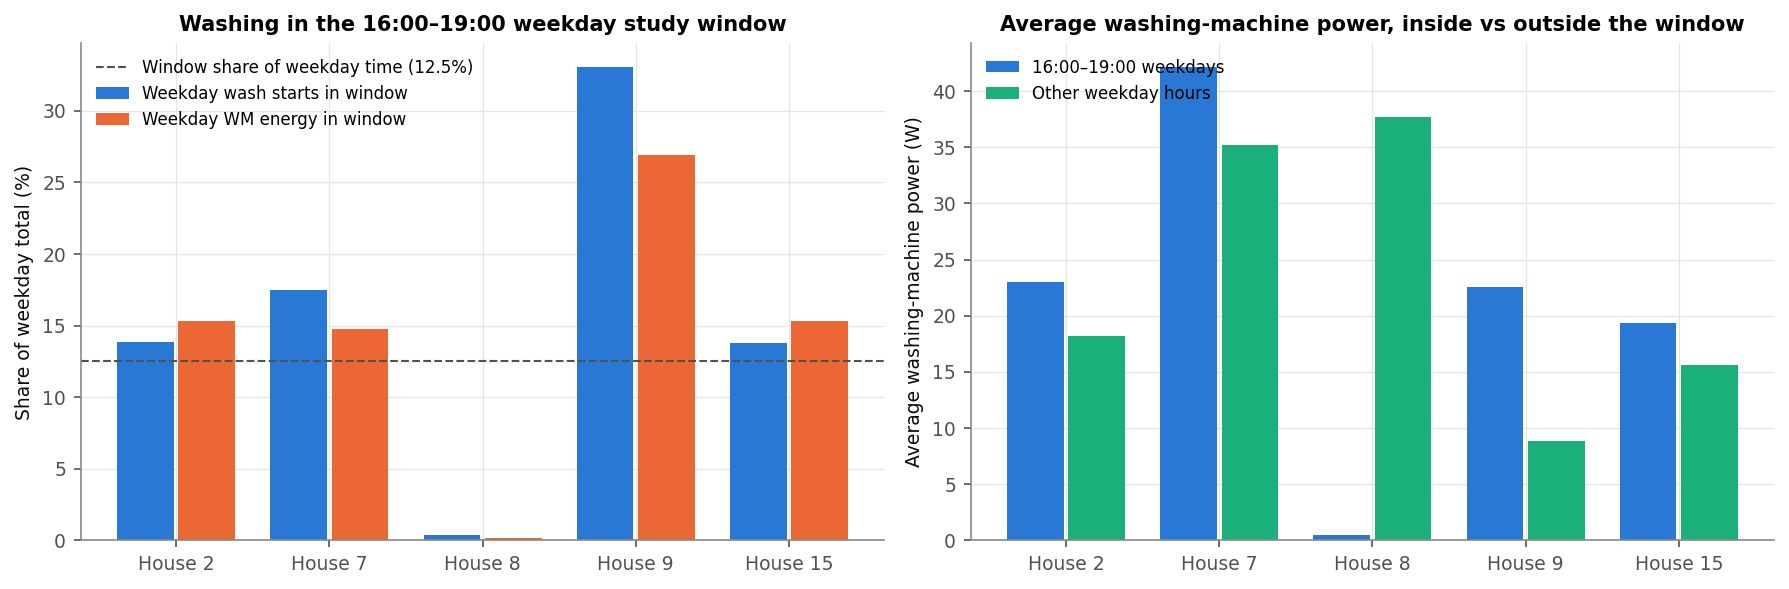

In [3]:
cols = ["house", "weekday_likely_cycles", "weekday_cycles_starting_in_window", "pct_weekday_starts_in_window",
        "pct_weekday_wm_energy_in_window", "mean_wm_w_in_window", "mean_wm_w_weekday_outside_window",
        "annual_wm_kwh_in_window_est", "mean_aggregate_kw_in_window", "wm_share_of_window_aggregate_pct",
        "window_kwh_from_cycles_started_in_window", "window_kwh_from_cycles_started_earlier",
        "window_kwh_outside_likely_cycles", "median_frac_energy_inside_window_for_window_starts"]
display(res["exposure"][cols].round(3))
display(Image(filename=str(res["figs"][0])))

**Interpretation.** Pooled, the share of weekday washes starting in the window is only slightly above the window's
share of weekday time (12.5%). The excess comes from House 9 and, to a lesser degree, House 7. House 8 starts
almost none, because it washes overnight. The washing machine's average contribution to the window is tens of
watts per household, a small slice of whole-house window demand. Some window energy comes from cycles that started
*before* 16:00, which a "start later" message would not move. Cycles that start in the window keep most of their
energy inside it, so a start would have to move well clear of the window, not just by a few minutes, for the
whole cycle to leave it.

## 3 · Can the model identify peak-window washing? (Phase 3 test periods only)

Actual and predicted cycles use exactly the same Phase 3 test rows (same usability masks), the same cycle rule,
the same weekday/window definition, and the Phase 3 thresholds (within-house τ, and each leave-one-house-out
fold's own τ). The headline matching is **one-to-one at IoU ≥ 0.5**; "any overlap" is a labelled sensitivity
check only.

Headline: one-to-one matching, IoU >= 0.5


,setting,house,actual_window_starts,actual_weekday_cycles,actual_pct_window_starts,pred_window_starts,pred_weekday_cycles,pred_pct_window_starts,error_pct_points,window_recall,window_precision,actual_mean_wm_w_in_window,pred_mean_wm_w_in_window,mean_w_error_w
0,within-house,2,4.0,48.0,8.333,33.0,117.0,28.205,19.872,0.000,0.000,12.371,28.162,15.791
1,within-house,7,30.0,142.0,21.127,48.0,203.0,23.645,2.519,0.633,0.375,48.534,41.367,-7.167
2,within-house,8,0.0,62.0,0.000,9.0,134.0,6.716,6.716,NaN,0.000,0.001,6.168,6.166
3,within-house,9,6.0,23.0,26.087,29.0,84.0,34.524,8.437,0.333,0.069,16.270,20.340,4.070
4,within-house,15,4.0,36.0,11.111,3.0,33.0,9.091,-2.020,0.750,1.000,17.836,10.961,-6.875
5,leave-one-house-out,2,4.0,48.0,8.333,30.0,105.0,28.571,20.238,0.000,0.000,12.371,26.186,13.815
6,leave-one-house-out,7,30.0,142.0,21.127,53.0,242.0,21.901,0.774,0.600,0.302,48.534,42.412,-6.122
7,leave-one-house-out,8,0.0,62.0,0.000,13.0,207.0,6.280,6.280,NaN,0.000,0.001,10.498,10.496
8,leave-one-house-out,9,6.0,23.0,26.087,36.0,136.0,26.471,0.384,0.667,0.111,16.270,29.406,13.136
9,leave-one-house-out,15,4.0,36.0,11.111,3.0,33.0,9.091,-2.020,0.000,0.000,17.836,7.642,-10.194


Sensitivity only: one-to-one matching, any overlap


,setting,house,window_recall,window_precision
10,within-house,2,1.000,0.121
11,within-house,7,0.933,0.500
12,within-house,8,NaN,0.000
13,within-house,9,1.000,0.207
14,within-house,15,0.750,1.000
15,leave-one-house-out,2,1.000,0.133
16,leave-one-house-out,7,0.800,0.377
17,leave-one-house-out,8,NaN,0.000
18,leave-one-house-out,9,0.833,0.139
19,leave-one-house-out,15,0.750,1.000


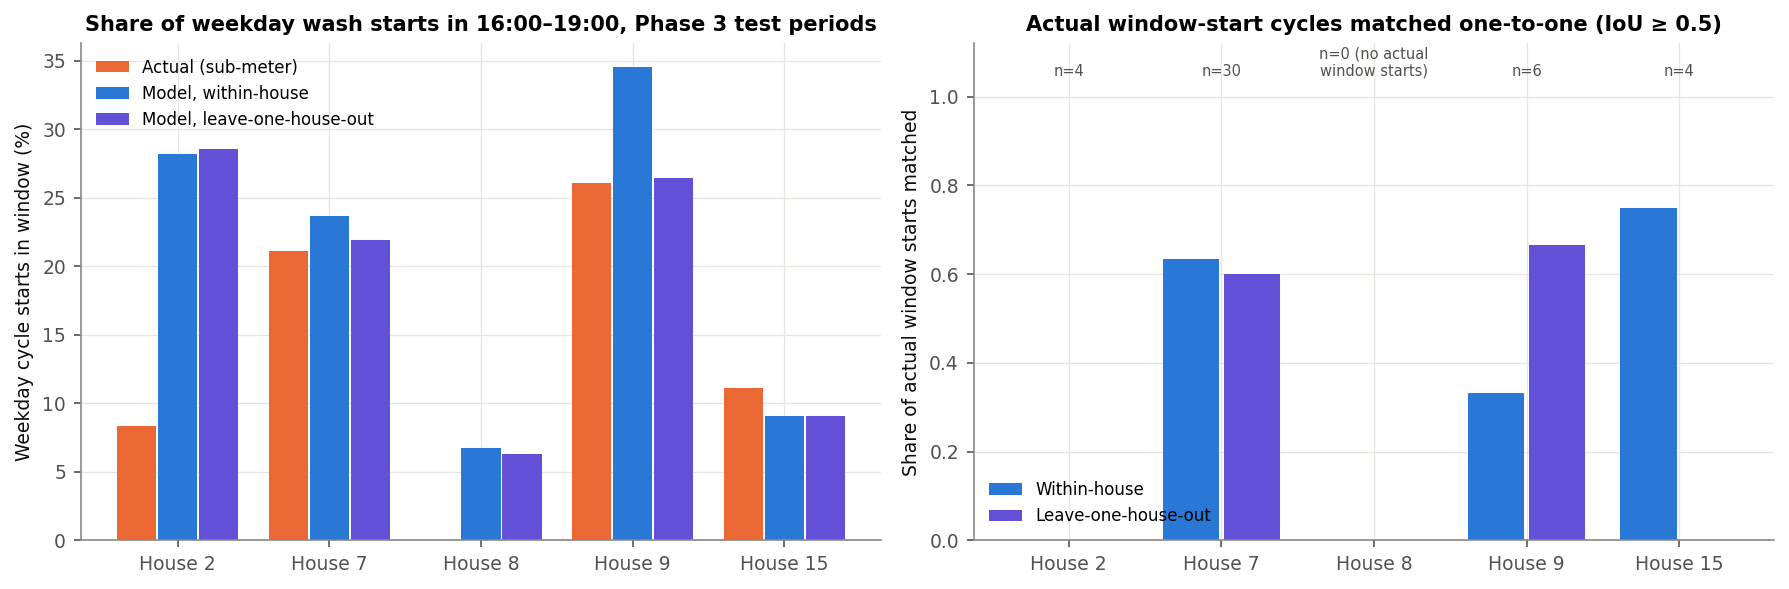

In [4]:
c = res["cmp"]
cols = ["setting", "house", "actual_window_starts", "actual_weekday_cycles", "actual_pct_window_starts",
        "pred_window_starts", "pred_weekday_cycles", "pred_pct_window_starts", "error_pct_points",
        "window_recall", "window_precision", "actual_mean_wm_w_in_window", "pred_mean_wm_w_in_window", "mean_w_error_w"]
print("Headline: one-to-one matching, IoU >= 0.5")
display(c[c.criterion == "one-to-one IoU>=0.5"][cols].round(3))
print("Sensitivity only: one-to-one matching, any overlap")
display(c[c.criterion != "one-to-one IoU>=0.5"][["setting", "house", "window_recall", "window_precision"]].round(3))
display(Image(filename=str(res["figs"][1])))

**Interpretation.** The model **over-states** how much washing starts in the window (most clearly in House 2),
and with strict matching it recovers only part of the actual window-start washes while most of its predicted
window starts are not real washes. The test periods contain few window starts per house, so these per-house
figures are uncertain. The model is therefore **not reliable enough to target individual households or to
measure a programme's effect**; at most it can give a rough first screen, to be confirmed with the customer or
with direct meter data.

## 4 · Secondary idea: cold washing (context only — no savings estimate)

The share of sub-metered WM energy drawn while the heater is on (1-minute power > 1 kW) shows that heating
dominates washing-machine energy. This is **measured data, not a model output, and not a savings estimate**:
a cooler wash still heats water to a lower temperature, and the model under-estimates heater energy (Phase 3).

In [5]:
display(res["heat"].round(2))

,house,wm_kwh,pct_wm_energy_while_heating
0,2,196.60,79.22
1,7,462.38,77.49
2,8,336.26,89.16
3,9,169.57,81.57
4,15,194.87,78.77
5,pooled,1359.69,81.32


## 5 · What 15- or 30-minute data would lose (illustration — no model is trained)

The same Phase 3 test data are averaged to clock-aligned 15- and 30-minute intervals (an interval counts only if
all its minutes are present). For each heated, complete true cycle: *signal* = the highest interval-average WM
power during the cycle; *noise* = SD of interval-to-interval changes in the other load (aggregate − WM) when the
WM is off. Ratio = signal ÷ noise.

> **Limitation:** this illustrates information loss. It is **not** a validated 15-/30-minute disaggregation model,
> and the visibility ratio is a simple heuristic, not a detection rate.

,house,resolution_min,heated_complete_cycles,median_signal_w,noise_std_w,median_visibility_ratio,pct_cycles_ratio_ge_2,pct_off_intervals_other_step_ge_median_signal
0,2,1,56,2085.944,412.162,5.061,100.000,0.701
1,2,15,56,1523.813,770.838,1.977,48.214,4.477
2,2,30,56,1016.569,621.955,1.634,1.786,6.394
3,7,1,193,2089.333,276.765,7.549,100.000,0.300
4,7,15,193,1383.177,434.873,3.181,90.674,3.025
5,7,30,193,829.405,431.766,1.921,44.041,8.113
6,8,1,68,2319.944,528.353,4.391,100.000,0.805
7,8,15,68,2175.938,709.238,3.068,89.706,3.285
8,8,30,68,1458.897,775.480,1.881,39.706,6.719
9,9,1,48,2223.000,407.905,5.450,100.000,0.647


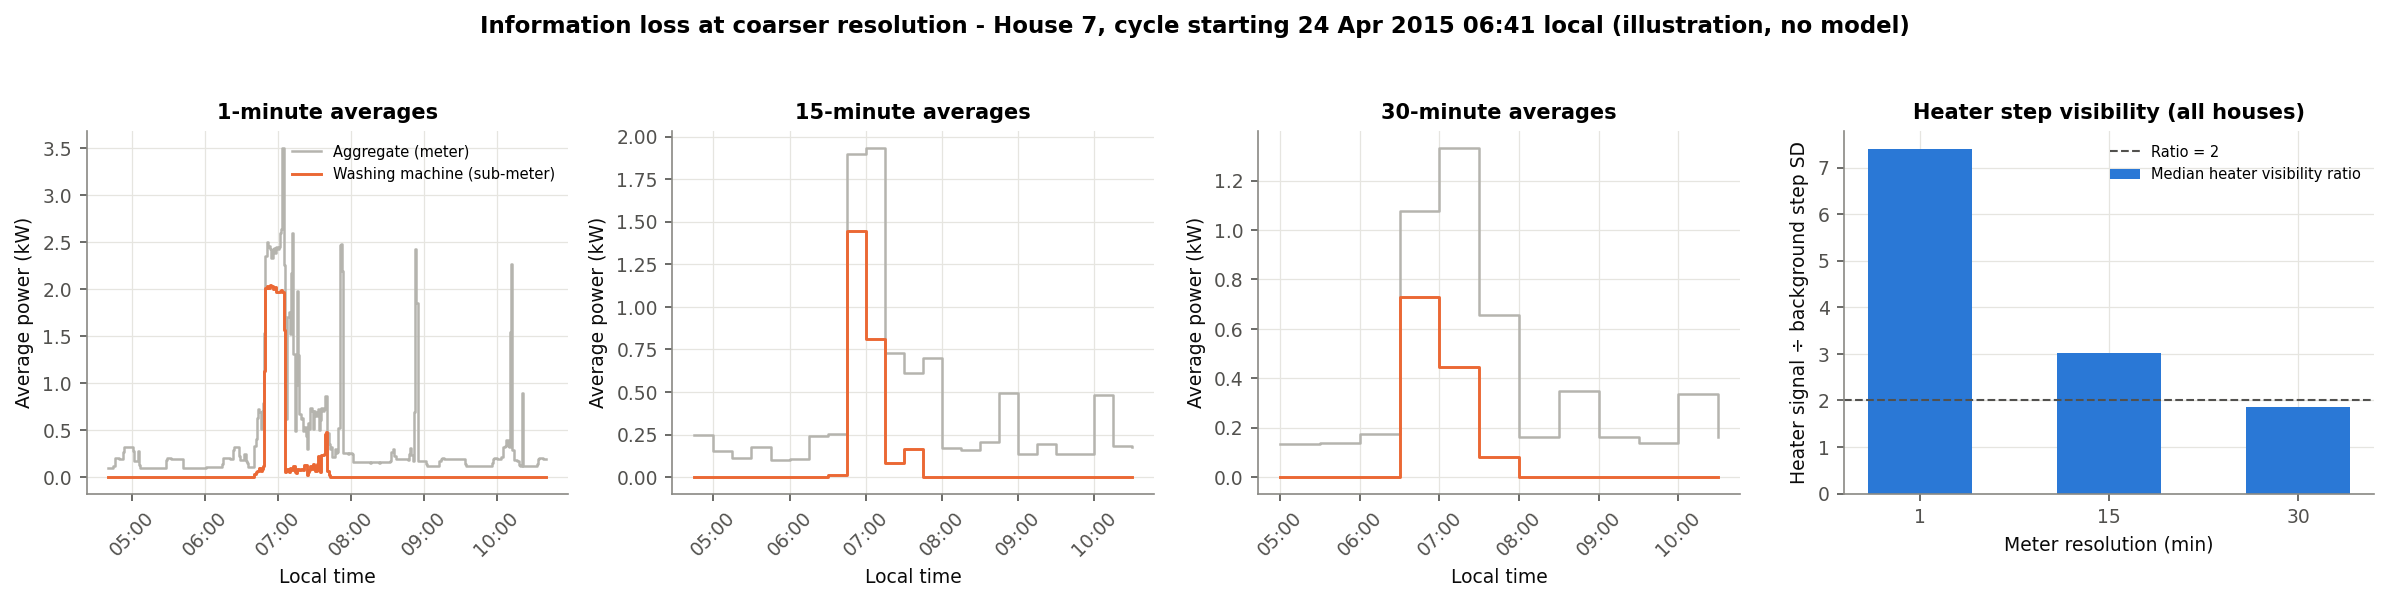

In [6]:
display(res["res_t"].round(3))
display(Image(filename=str(res["figs"][2])))

**Interpretation.** Averaging spreads the ~2 kW, 10–20-minute heater block across the interval, so its height
falls while the background changes between intervals grow. The ratio drops sharply from 1 to 30 minutes, and the
share of WM-off intervals in which some other load changes by as much as a typical heater block rises. Only the
quiet single-occupant House 15 keeps a clearly visible step.

## 6 · Illustrative pilot sample size

How many households per arm a simple two-arm comparison would need to detect a drop in average 16:00–19:00
whole-house kW, if the drop were all, half or a quarter of the pooled average WM power in the window. The SD comes
from only five REFIT homes.

> **Limitation:** this is illustrative only. A real pilot must estimate variance from its own baseline data;
> adjusting for each home's pre-period (ANCOVA) or using within-home designs would reduce the numbers.

In [7]:
display(res["ss"].round(4))

,assumed_reduction_share_of_wm_window_power,assumed_reduction_kw,sigma_between_household_kw,households_per_arm
0,1.00,0.0219,0.2775,2514
1,0.50,0.0110,0.2775,10053
2,0.25,0.0055,0.2775,40212


## 7 · Saved outputs

In [8]:
print("\n".join(str(p.relative_to(a.ROOT)) for p in sorted(a.TAB_DIR.glob("*.csv"))))
print("\n".join(str(p.relative_to(a.ROOT)) for p in res["figs"]))

outputs/tables/phase4/01_dst_window_check.csv
outputs/tables/phase4/02_peak_window_exposure.csv
outputs/tables/phase4/03_window_start_cycles.csv
outputs/tables/phase4/04_heating_energy_share.csv
outputs/tables/phase4/05_model_vs_actual_window_starts.csv
outputs/tables/phase4/06_resolution_visibility.csv
outputs/tables/phase4/07_resolution_visibility_by_cycle.csv
outputs/tables/phase4/08_illustrative_sample_size.csv
outputs/tables/phase4/09_resolution_example.csv
outputs/figures/phase4/01_peak_window_exposure.png
outputs/figures/phase4/02_model_vs_actual_window_starts.png
outputs/figures/phase4/03_resolution_information_loss.png
